In [7]:
import pandas as pd

df = pd.read_csv(r'C:\Users\Анна\Desktop\my-first-project\data\62002 Titanic-Dataset.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Анна\\Desktop\\my-first-project\\data\\62002 Titanic-Dataset.csv'

In [8]:
import os

path = r'C:\Users\Анна\Desktop\my-first-project\data\62002 Titanic-Dataset.csv'
print(os.path.exists(path))
print(os.listdir(r'C:\Users\Анна\Desktop\my-first-project\data'))

False
['.ipynb_checkpoints', 'Titanic-Dataset.csv']


In [9]:
df = pd.read_csv(r'C:\Users\Анна\Desktop\my-first-project\data\Titanic-Dataset.csv')
df.head()

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0


In [10]:
df.head()

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0


In [11]:
df.isnull().sum()

Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Embarked         2
Ticket           0
Fare             0
Cabin          687
PassengerId      0
Pclass           0
Survived         0
dtype: int64

In [13]:
df = df.drop(columns=['Cabin'])

In [14]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [15]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [16]:
df.isnull().sum()

Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Embarked       0
Ticket         0
Fare           0
PassengerId    0
Pclass         0
Survived       0
dtype: int64

In [17]:
df['Survived'].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [18]:
df.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [19]:
df.groupby('Pclass')['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [21]:
df.groupby(['Sex', 'Pclass'])['Survived'].mean() * 100

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

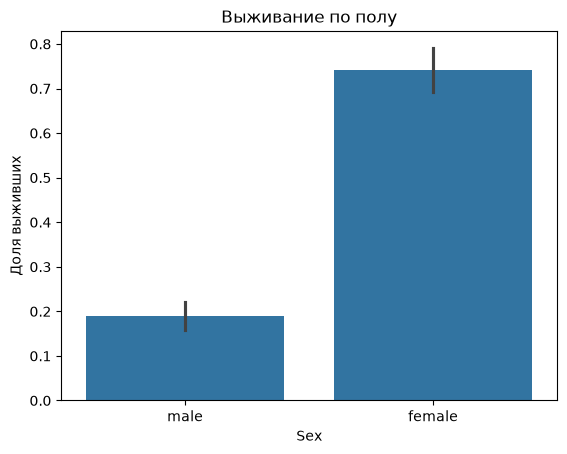

In [23]:
sns.barplot(x='Sex', y='Survived', data=df)
plt.title('Выживание по полу')
plt.ylabel('Доля выживших')
plt.show()

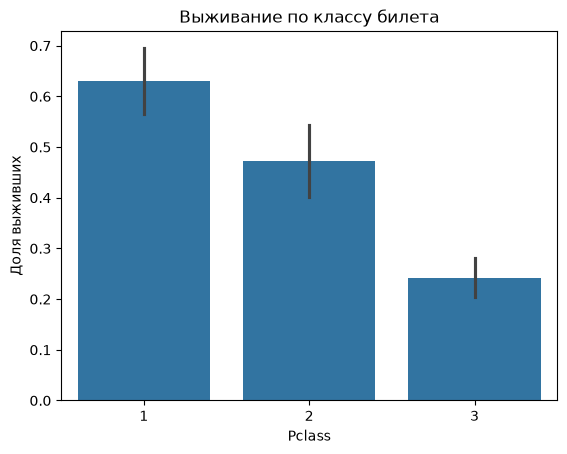

In [24]:
sns.barplot(x='Pclass', y='Survived', data=df)
plt.title('Выживание по классу билета')
plt.ylabel('Доля выживших')
plt.show()

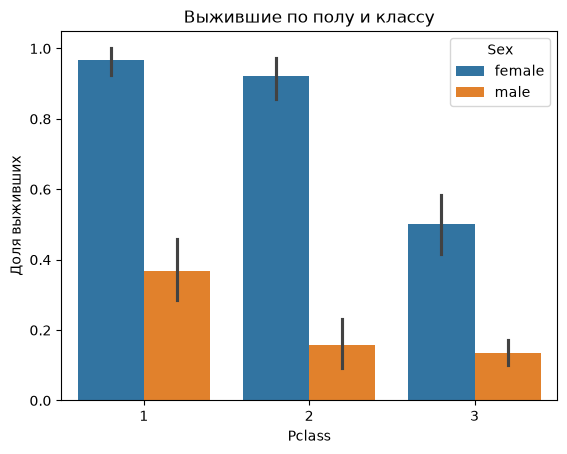

In [25]:
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df)
plt.title('Выжившие по полу и классу')
plt.ylabel('Доля выживших')
plt.show()

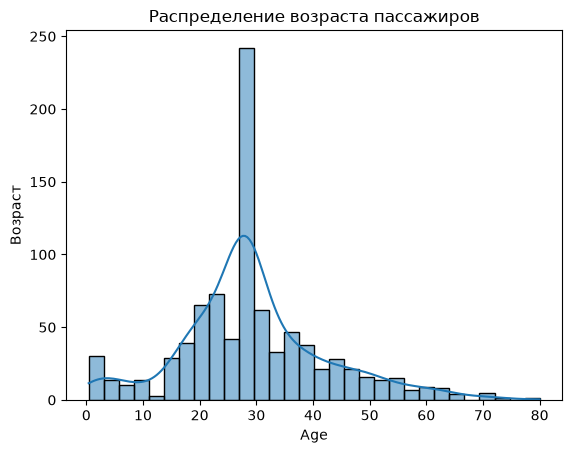

In [26]:
sns.histplot(df['Age'], bins=30, kde=True)
plt.title('Распределение возраста пассажиров')
plt.ylabel('Возраст')
plt.show()

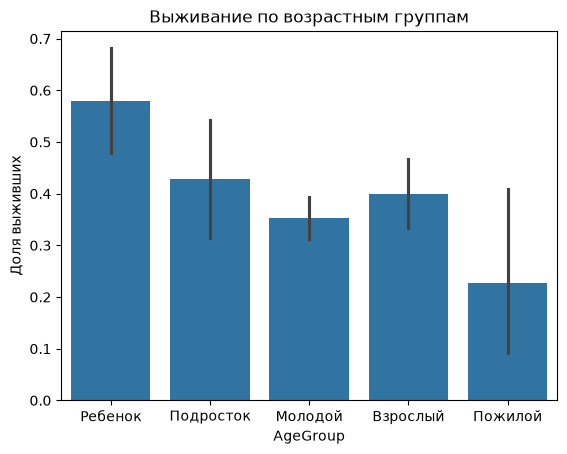

In [29]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100],
                        labels=['Ребенок', 'Подросток', 'Молодой', 'Взрослый', 'Пожилой'])

sns.barplot(x='AgeGroup', y='Survived', data=df)
plt.title('Выживание по возрастным группам')
plt.ylabel('Доля выживших')
plt.show()

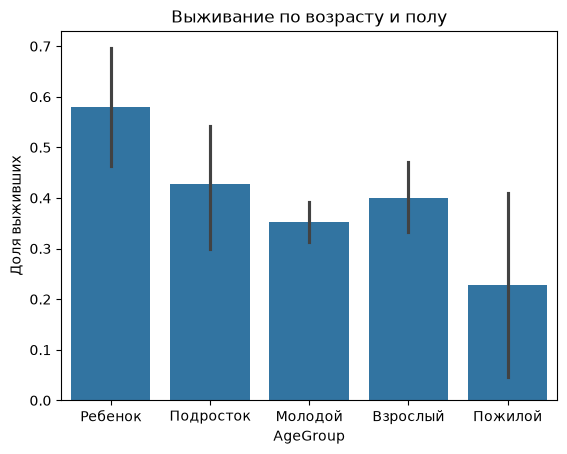

In [30]:
sns.barplot(x='AgeGroup', y='Survived', data=df)
plt.title('Выживание по возрасту и полу')
plt.ylabel('Доля выживших')
plt.show()

In [32]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

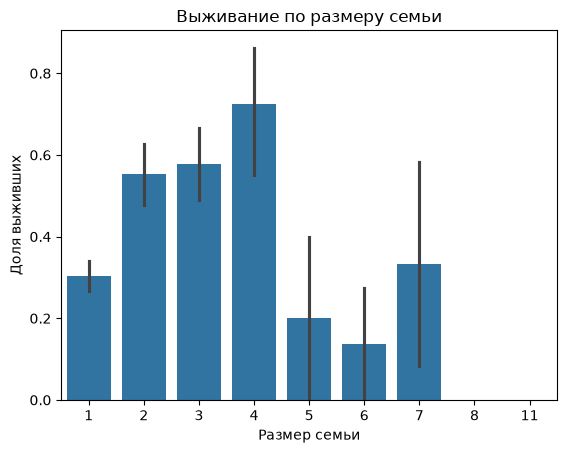

In [33]:
sns.barplot(x='FamilySize', y='Survived', data=df)
plt.title('Выживание по размеру семьи')
plt.ylabel('Доля выживших')
plt.xlabel('Размер семьи')
plt.show()

In [34]:
df.groupby('FamilySize')['Survived'].mean() * 100

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

In [35]:
print("===КЛЮЧЕВЫЕ ВЫВОДЫ ПО TITANIC ===\n")

print("1. ОБЩЕЕ ВЫЖИВАНИЕ:")
print(f"    Выжило: {df['Survived'].mean()*100:.1f}")
print(f"    Погибло: {(1-df['Survived'].mean())*100:.1f}%\n")

print("2. ПОЛ:")
print(df.groupby('Sex')['Survived'].mean().mul(100).round(1).to_string(), "\n")

print("3. КЛАСС:")
print(df.groupby('Pclass')['Survived'].mean().mul(100).round(1).to_string(), "\n" )

print("4. ПОЛ + КЛАСС:")
print(df.groupby(['Sex', 'Pclass'])['Survived'].mean().mul(100).round(1).to_string(), "\n")

print("5. ВОЗРАСТ:")
print(df.groupby('AgeGroup')['Survived'].mean().mul(100).round(1).to_string(), "\n")

print("6. РАЗМЕР СЕМЬИ:")
print(df.groupby('FamilySize')['Survived'].mean().mul(100).round(1).to_string(), "\n")


===КЛЮЧЕВЫЕ ВЫВОДЫ ПО TITANIC ===

1. ОБЩЕЕ ВЫЖИВАНИЕ:
    Выжило: 38.4
    Погибло: 61.6%

2. ПОЛ:
Sex
female    74.2
male      18.9 

3. КЛАСС:
Pclass
1    63.0
2    47.3
3    24.2 

4. ПОЛ + КЛАСС:
Sex     Pclass
female  1         96.8
        2         92.1
        3         50.0
male    1         36.9
        2         15.7
        3         13.5 

5. ВОЗРАСТ:
AgeGroup
Ребенок      58.0
Подросток    42.9
Молодой      35.3
Взрослый     40.0
Пожилой      22.7 

6. РАЗМЕР СЕМЬИ:
FamilySize
1     30.4
2     55.3
3     57.8
4     72.4
5     20.0
6     13.6
7     33.3
8      0.0
11     0.0 



In [36]:
df.to_csv(r'C:\Users\Анна\Desktop\my-first-project\data\titanic_clean.csv', index=False)
print("Данные сохранены")

Данные сохранены


In [37]:
plt.savefig(r'C:\Users\Анна\Desktop\my-first-project\visualizations\survival_by_sex.png', dpi=100, bbox_inches='tight'

_IncompleteInputError: incomplete input (2851975710.py, line 1)